### pan_cancer 六分类

In [ ]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.model_selection import StratifiedGroupKFold

#### Fscore

In [4]:
# 加载数据集
file_path = '../Fscore/pan_sample_6_labeled_FscoreSorted_selected94.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["source_id"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='log_loss', path=model_path).fit(
        train_data=train_data,
        # presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        num_bag_folds=0,
        num_cpus=4
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_micro', 'f1_weighted'])
    return leaderboard

In [6]:
pan6_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "pan cancer6", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       243.30 GB / 251.54 GB (96.7%)
Disk Space Avail:   8908.46 GB / 14784.53 GB (60.3%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets.
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='best_quality'   : Maximize accuracy. Default time_limit=3600.
	presets='high_quality'   : Strong accuracy with fast inference speed. Default time_limit=3600.
	presets='good_quality'   : Good accuracy with very fast inference speed. Default time_limit=3600.
	presets='medium_quality' : Fast training time, ideal for initial prototyping.
Beginning Au

In [7]:
pan6_leaderboard_Fscore.to_csv("pan6_leaderboard_Fscore.csv", index=False)
pan6_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,f1_macro,f1_micro,f1_weighted,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-0.895733,0.638783,0.607697,0.596990,0.638783,0.620703,-0.861923,log_loss,0.164161,0.135764,13.094230,0.002874,0.001232,0.085759,2,True,5
1,XGBoost,-0.938998,0.646388,0.613930,0.600624,0.646388,0.625396,-0.918466,log_loss,0.030227,0.005433,4.420714,0.030227,0.005433,4.420714,1,True,4
2,LightGBM,-0.955586,0.638783,0.609672,0.598661,0.638783,0.619277,-0.908887,log_loss,0.013427,0.003359,2.481834,0.013427,0.003359,2.481834,1,True,2
3,RandomForest,-0.965725,0.684411,0.652359,0.639186,0.684411,0.663970,-0.917821,log_loss,0.096752,0.105956,1.601490,0.096752,0.105956,1.601490,1,True,3
4,NeuralNetFastAI,-1.137174,0.593156,0.573388,0.575973,0.593156,0.589196,-1.173148,log_loss,0.020881,0.019783,4.504434,0.020881,0.019783,4.504434,1,True,1


In [36]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/Fscore'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(Fscoredata, test_size=0.2, random_state=42, stratify=Fscoredata['class'])

使用的最佳模型是: WeightedEnsemble_L2


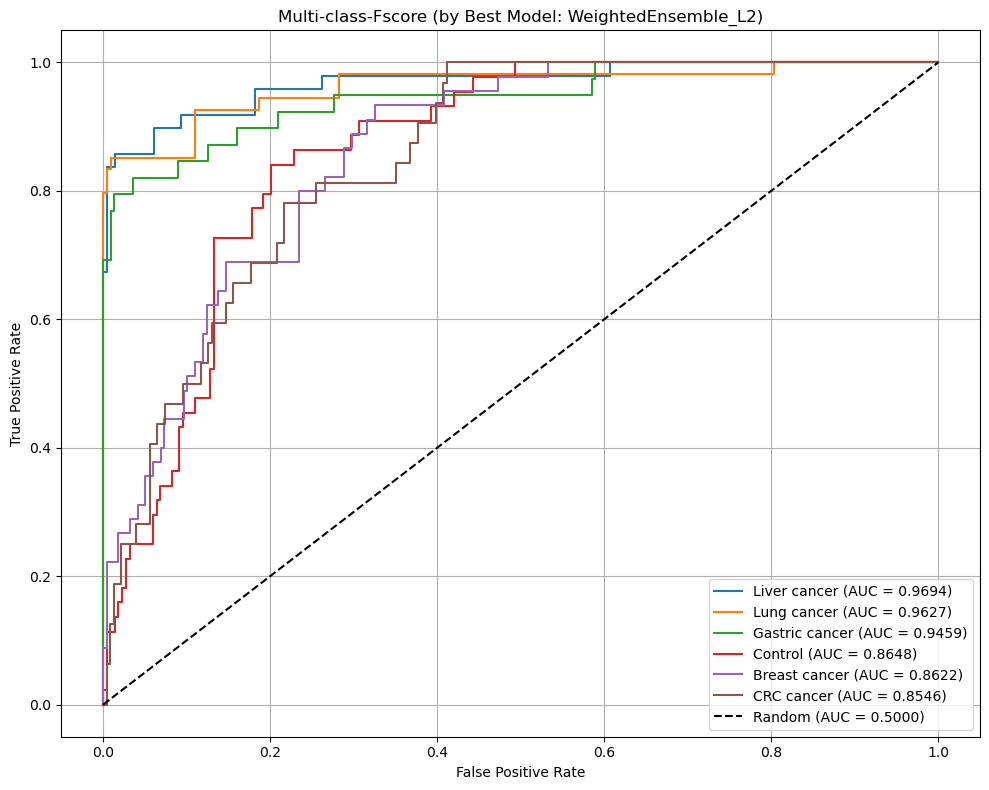

In [ ]:
def calculate_and_plot_multiclass_auc_Fscore(predictor, test_data, model_dir):
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize

    # 标签映射
    label_mapping = {
        0: 'Control',
        1: 'pancancer cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    # 真实标签
    y_true = test_data[predictor.label]

    # 使用最佳模型进行预测
    best_model = predictor.model_best
    print(f"使用的最佳模型是: {best_model}")
    y_proba = predictor.predict_proba(test_data, model=best_model)

    # 转换真实标签为 One-vs-Rest 格式
    classes = predictor.class_labels
    y_true_bin = label_binarize(y_true, classes=classes)

    # 计算每个类别的 ROC 曲线和 AUC
    roc_data = []

    # for i, class_label in enumerate(classes):
    #     fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i])
    #     auc_val = auc(fpr, tpr)
    #     roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    for i, class_label in enumerate(classes):
        sample_weight = y_true_bin[:, i] * 5 + (1 - y_true_bin[:, i])  # 正类权重为 5，负类为 1
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i], sample_weight=sample_weight)
        auc_val = auc(fpr, tpr)
        roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    # 按 AUC 从高到低排序
    roc_data.sort(key=lambda x: x[3], reverse=True)

    # 绘图
    plt.figure(figsize=(10, 8))
    for label, fpr, tpr, auc_val in roc_data:
        plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_val:.4f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5000)')
    plt.title(f"Multi-class-Fscore (by Best Model: {best_model})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

    # return {label: auc_val for label, _, _, auc_val in roc_data}

calculate_and_plot_multiclass_auc_Fscore(predictor, test_data, model_dir=model_dir)

##### ANOVA

In [20]:
# 加载数据集
file_path = '../ANOVA/pan_sample_6_labeled_AnovaSorted_selected85.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["source_id"]
        )
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='log_loss', path=model_path).fit(
        train_data=train_data,
        # presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        num_bag_folds=0,
        num_cpus=4
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_micro', 'f1_weighted'])
    return leaderboard

In [28]:
pan6_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "pan cancer6", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       242.61 GB / 251.54 GB (96.4%)
Disk Space Avail:   8900.92 GB / 14784.53 GB (60.2%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets.
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='best_quality'   : Maximize accuracy. Default time_limit=3600.
	presets='high_quality'   : Strong accuracy with fast inference speed. Default time_limit=3600.
	presets='good_quality'   : Good accuracy with very fast inference speed. Default time_limit=3600.
	presets='medium_quality' : Fast training time, ideal for initial prototyping.
Beginning Au

In [29]:
pan6_leaderboard_ANOVA.to_csv("pan6_leaderboard_ANOVA.csv", index=False)
pan6_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,f1_macro,f1_micro,f1_weighted,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-0.874804,0.676806,0.650224,0.643948,0.676806,0.662736,-0.842157,log_loss,0.184079,0.150627,13.697610,0.002998,0.001258,0.087564,2,True,5
1,RandomForest,-0.954640,0.692015,0.661030,0.657221,0.692015,0.680296,-0.920578,log_loss,0.109809,0.119081,1.486300,0.109809,0.119081,1.486300,1,True,3
2,LightGBM,-0.961545,0.638783,0.608336,0.595526,0.638783,0.617816,-0.883637,log_loss,0.019623,0.002963,2.401783,0.019623,0.002963,2.401783,1,True,2
3,XGBoost,-0.975718,0.646388,0.619856,0.612781,0.646388,0.631233,-0.915920,log_loss,0.031950,0.005998,4.184913,0.031950,0.005998,4.184913,1,True,4
4,NeuralNetFastAI,-1.082726,0.650190,0.618319,0.614762,0.650190,0.638730,-1.146826,log_loss,0.019699,0.021328,5.537050,0.019699,0.021328,5.537050,1,True,1


In [31]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/ANOVA'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(ANOVAdata, test_size=0.2, random_state=42, stratify=ANOVAdata['class'])

使用的最佳模型是: WeightedEnsemble_L2


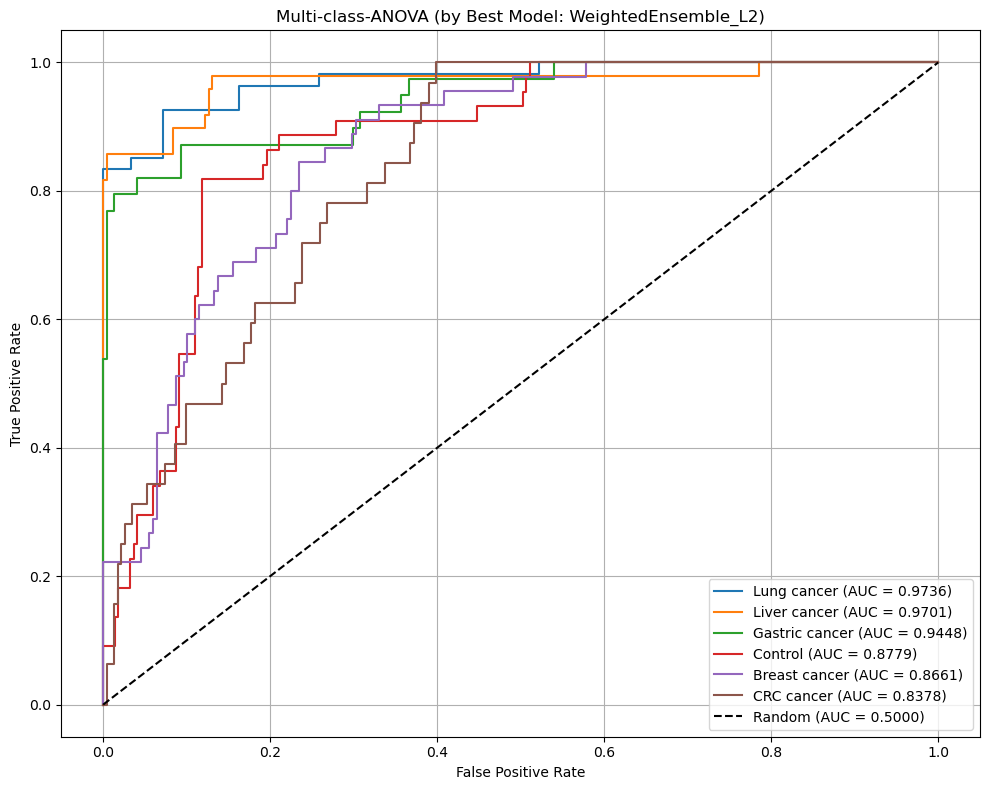

In [ ]:
def calculate_and_plot_multiclass_auc_ANOVA(predictor, test_data, model_dir):
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize

    # 标签映射
    label_mapping = {
        0: 'Control',
        1: 'pancancer cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    # 真实标签
    y_true = test_data[predictor.label]

    # 使用最佳模型进行预测
    best_model = predictor.model_best
    print(f"使用的最佳模型是: {best_model}")
    y_proba = predictor.predict_proba(test_data, model=best_model)

    # 转换真实标签为 One-vs-Rest 格式
    classes = predictor.class_labels
    y_true_bin = label_binarize(y_true, classes=classes)

    # 计算每个类别的 ROC 曲线和 AUC
    roc_data = []
    
    # for i, class_label in enumerate(classes):
    #     fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i])
    #     auc_val = auc(fpr, tpr)
    #     roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    for i, class_label in enumerate(classes):
        sample_weight = y_true_bin[:, i] * 5 + (1 - y_true_bin[:, i])  # 正类权重为 5，负类为 1
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i], sample_weight=sample_weight)
        auc_val = auc(fpr, tpr)
        roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    # 按 AUC 从高到低排序
    roc_data.sort(key=lambda x: x[3], reverse=True)

    # 绘图
    plt.figure(figsize=(10, 8))
    for label, fpr, tpr, auc_val in roc_data:
        plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_val:.4f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5000)')
    plt.title(f"Multi-class-ANOVA (by Best Model: {best_model})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

    # return {label: auc_val for label, _, _, auc_val in roc_data}

calculate_and_plot_multiclass_auc_ANOVA(predictor, test_data, model_dir=model_dir)

##### ReliefF

In [5]:
# 加载数据集
file_path = '../ReliefF/pan_sample_6_labeled_ReliefFSorted_selected42.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["source_id"]
        )
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='log_loss', path=model_path).fit(
        train_data=train_data,
        # presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        num_bag_folds=0,
        num_cpus=4
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_micro', 'f1_weighted'])
    return leaderboard

In [43]:
pan6_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "pan cancer6", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #59~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Mar 19 17:07:41 UTC 2
CPU Count:          48
Memory Avail:       189.30 GB / 251.54 GB (75.3%)
Disk Space Avail:   7175.66 GB / 14784.53 GB (48.5%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets.
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='best_quality'   : Maximize accuracy. Default time_limit=3600.
	presets='high_quality'   : Strong accuracy with fast inference speed. Default time_limit=3600.
	presets='good_quality'   : Good accuracy with very fast inference speed. Default time_limit=3600.
	presets='medium_quality' : Fast training time, ideal for initial prototyping.
Beginning Au

In [44]:
pan6_leaderboard_ReliefF.to_csv("pan6_leaderboard_ReliefF.csv", index=False)
pan6_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,f1_macro,f1_micro,f1_weighted,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-0.527979,0.809524,0.804112,0.803431,0.809524,0.807108,-0.631817,log_loss,0.193086,0.144412,11.235884,0.004272,0.001490,0.102098,2,True,5
1,LightGBM,-0.560858,0.795918,0.790191,0.790281,0.795918,0.794370,-0.667998,log_loss,0.016438,0.004008,2.479614,0.016438,0.004008,2.479614,1,True,2
2,XGBoost,-0.591925,0.802721,0.797077,0.795391,0.802721,0.799351,-0.686921,log_loss,0.034166,0.005878,3.072262,0.034166,0.005878,3.072262,1,True,4
3,RandomForest,-0.671622,0.789116,0.783401,0.781879,0.789116,0.786344,-0.708875,log_loss,0.100780,0.116509,1.361345,0.100780,0.116509,1.361345,1,True,3
4,NeuralNetFastAI,-0.876196,0.690476,0.685210,0.683450,0.690476,0.687446,-0.872484,log_loss,0.037430,0.016526,4.220565,0.037430,0.016526,4.220565,1,True,1


In [9]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/ReliefF'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(ReliefFdata, test_size=0.2, random_state=42, stratify=ReliefFdata['class'])

使用的最佳模型是: WeightedEnsemble_L2


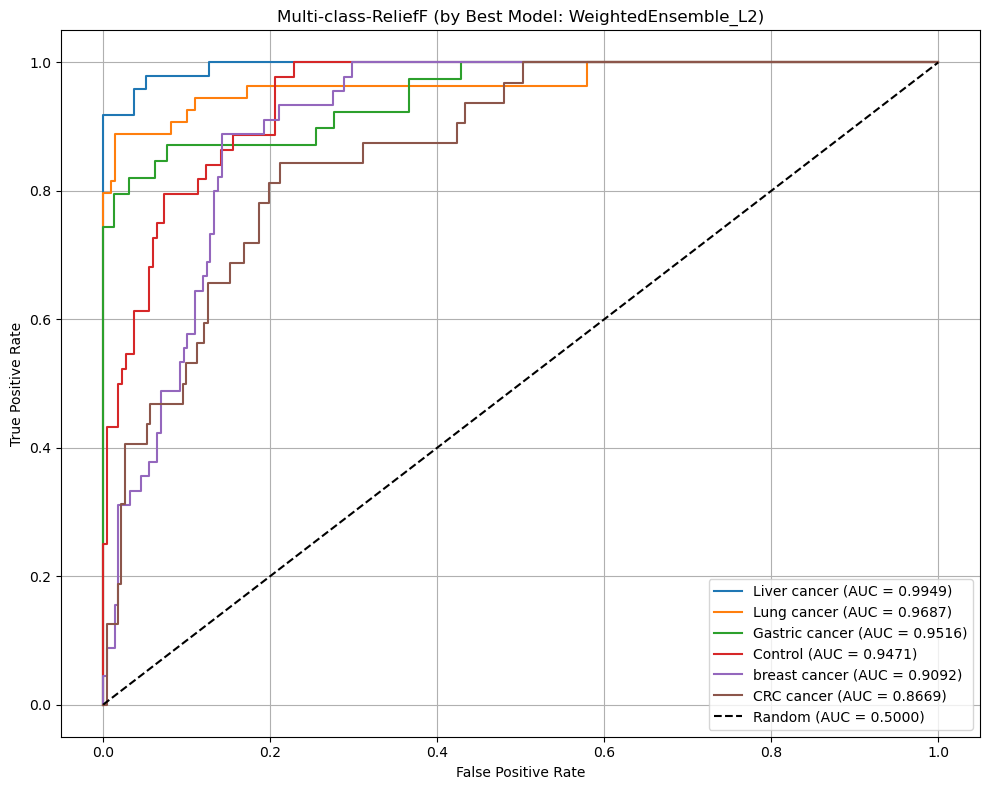

In [ ]:
def calculate_and_plot_multiclass_auc_ReliefF(predictor, test_data, model_dir):
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize

    # 标签映射
    label_mapping = {
        0: 'Control',
        1: 'breast cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    # 真实标签
    y_true = test_data[predictor.label]

    # 使用最佳模型进行预测
    best_model = predictor.model_best
    print(f"使用的最佳模型是: {best_model}")
    y_proba = predictor.predict_proba(test_data, model=best_model)

    # 转换真实标签为 One-vs-Rest 格式
    classes = predictor.class_labels
    y_true_bin = label_binarize(y_true, classes=classes)

    # 计算每个类别的 ROC 曲线和 AUC
    roc_data = []

    for i, class_label in enumerate(classes):
        sample_weight = y_true_bin[:, i] * 5 + (1 - y_true_bin[:, i])  # 正类权重为 5，负类为 1
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i], sample_weight=sample_weight)
        auc_val = auc(fpr, tpr)
        roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    # 按 AUC 从高到低排序
    roc_data.sort(key=lambda x: x[3], reverse=True)

    # 绘图
    plt.figure(figsize=(10, 8))
    for label, fpr, tpr, auc_val in roc_data:
        plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_val:.4f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5000)')
    plt.title(f"Multi-class-ReliefF (by Best Model: {best_model})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

    # return {label: auc_val for label, _, _, auc_val in roc_data}

calculate_and_plot_multiclass_auc_ReliefF(predictor, test_data, model_dir=model_dir)

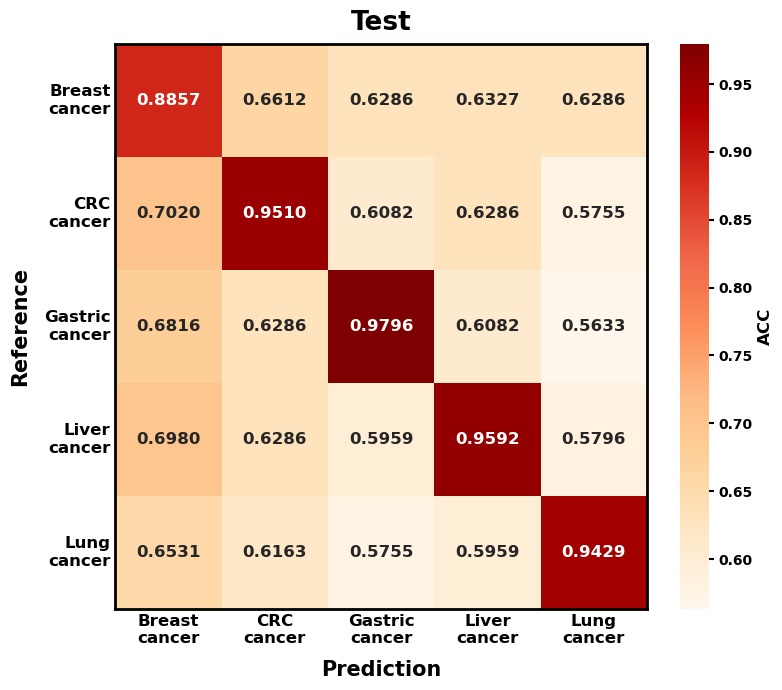

In [6]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/ReliefF'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(ReliefFdata, test_size=0.2, random_state=42, stratify=ReliefFdata['class'])

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import label_binarize
import numpy as np
import os

def plot_per_class_acc_matrix(predictor, data, model_dir):
    # 标签映射
    full_label_mapping = {
        0: 'Control',
        1: 'Breast cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    labels = [1, 2, 3, 4, 5]
    class_names = [full_label_mapping[i] for i in labels]

    y_true = data[predictor.label]
    y_pred = predictor.predict(data)
    class_labels = predictor.class_labels

    # 仅取癌症样本
    mask = y_true.isin(labels)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    # 二值化标签
    y_true_bin = label_binarize(y_true, classes=class_labels)
    y_pred_bin = label_binarize(y_pred, classes=class_labels)

    # 初始化 ACC 矩阵
    acc_matrix = np.zeros((len(labels), len(labels)))

    for i, true_class in enumerate(labels):
        for j, pred_class in enumerate(labels):
            y_true_binary = (y_true == true_class).astype(int)
            y_pred_binary = (y_pred == pred_class).astype(int)
            acc = accuracy_score(y_true_binary, y_pred_binary)
            acc_matrix[i, j] = acc

    # 构建注释文本
    annot = np.array([[f'{acc_matrix[i, j]:.4f}' for j in range(len(labels))] for i in range(len(labels))])

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(acc_matrix, annot=annot, fmt='', cmap='OrRd',
                xticklabels=[s.replace(' ', '\n') for s in class_names],
                yticklabels=[s.replace(' ', '\n') for s in class_names],
                cbar_kws={'label': 'ACC'},
                linewidths=0.0, ax=ax)

    # 样式设置
    ax.set_xlabel("Prediction", fontsize=15, fontweight='bold', labelpad=10)
    ax.set_ylabel("Reference", fontsize=15, fontweight='bold', labelpad=10)
    ax.set_title("Test", fontsize=19, fontweight='bold', pad=10)

    ax.set_xticklabels(ax.get_xticklabels(), fontsize=12, fontweight='bold', rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=12, fontweight='bold', rotation=0)
    # 去掉坐标轴刻度线
    ax.tick_params(axis='both', length=0)


    for text in ax.texts:
        text.set_fontsize(12)
        text.set_fontweight('bold')

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=10, width=1.5)

    # 图例刻度加粗
    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight('bold')

    cbar.ax.yaxis.label.set_fontsize(12)
    cbar.ax.yaxis.label.set_fontweight('bold')
    cbar.ax.yaxis.label.set_rotation(90)

    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_linewidth(2)
        spine.set_edgecolor('black')

    plt.tight_layout()
    os.makedirs(model_dir, exist_ok=True)
    plt.savefig(os.path.join(model_dir, "per_class_accuracy_matrix_Test.png"), dpi=300)
    plt.show()


plot_per_class_acc_matrix(predictor, test_data, model_dir)

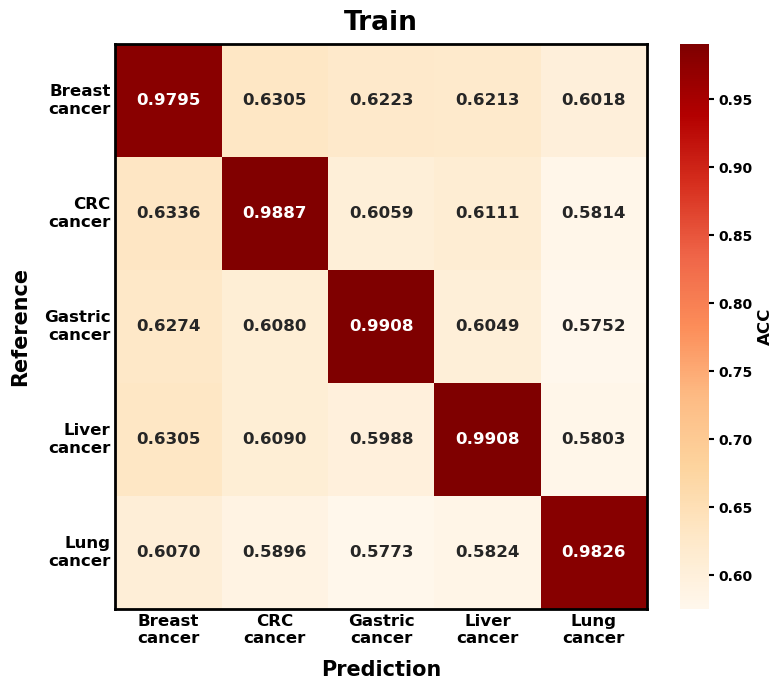

In [8]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/ReliefF'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(ReliefFdata, test_size=0.2, random_state=42, stratify=ReliefFdata['class'])

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import label_binarize
import numpy as np
import os

def plot_per_class_acc_matrix(predictor, data, model_dir):
    # 标签映射
    full_label_mapping = {
        0: 'Control',
        1: 'Breast cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    labels = [1, 2, 3, 4, 5]
    class_names = [full_label_mapping[i] for i in labels]

    y_true = data[predictor.label]
    y_pred = predictor.predict(data)
    class_labels = predictor.class_labels

    # 仅取癌症样本
    mask = y_true.isin(labels)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    # 二值化标签
    y_true_bin = label_binarize(y_true, classes=class_labels)
    y_pred_bin = label_binarize(y_pred, classes=class_labels)

    # 初始化 ACC 矩阵
    acc_matrix = np.zeros((len(labels), len(labels)))

    for i, true_class in enumerate(labels):
        for j, pred_class in enumerate(labels):
            y_true_binary = (y_true == true_class).astype(int)
            y_pred_binary = (y_pred == pred_class).astype(int)
            acc = accuracy_score(y_true_binary, y_pred_binary)
            acc_matrix[i, j] = acc

    # 构建注释文本
    annot = np.array([[f'{acc_matrix[i, j]:.4f}' for j in range(len(labels))] for i in range(len(labels))])

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(acc_matrix, annot=annot, fmt='', cmap='OrRd',
                xticklabels=[s.replace(' ', '\n') for s in class_names],
                yticklabels=[s.replace(' ', '\n') for s in class_names],
                cbar_kws={'label': 'ACC'},
                linewidths=0.0, ax=ax)

    # 样式设置
    ax.set_xlabel("Prediction", fontsize=15, fontweight='bold', labelpad=10)
    ax.set_ylabel("Reference", fontsize=15, fontweight='bold', labelpad=10)
    ax.set_title("Train", fontsize=19, fontweight='bold', pad=10)

    ax.set_xticklabels(ax.get_xticklabels(), fontsize=12, fontweight='bold', rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=12, fontweight='bold', rotation=0)
    # 去掉坐标轴刻度线
    ax.tick_params(axis='both', length=0)


    for text in ax.texts:
        text.set_fontsize(12)
        text.set_fontweight('bold')

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=10, width=1.5)

    # 图例刻度加粗
    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight('bold')

    cbar.ax.yaxis.label.set_fontsize(12)
    cbar.ax.yaxis.label.set_fontweight('bold')
    cbar.ax.yaxis.label.set_rotation(90)

    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_linewidth(2)
        spine.set_edgecolor('black')

    plt.tight_layout()
    os.makedirs(model_dir, exist_ok=True)
    plt.savefig(os.path.join(model_dir, "per_class_accuracy_matrix_Train.png"), dpi=300)
    plt.show()

plot_per_class_acc_matrix(predictor, train_data, model_dir)

使用的最佳模型是: WeightedEnsemble_L2


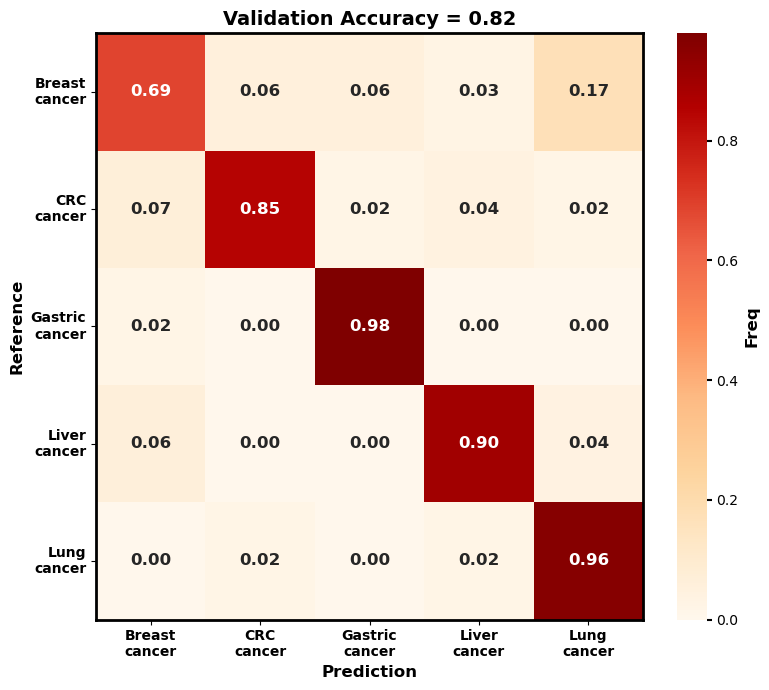

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score
import numpy as np
import os

def plot_multiclass_confusion_matrix_ReliefF(predictor, test_data, model_dir):
    full_label_mapping = {
        0: 'Control',
        1: 'Breast cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    labels = [1, 2, 3, 4, 5]
    class_names = [full_label_mapping[i] for i in labels]

    y_true = test_data[predictor.label]
    best_model = predictor.model_best
    print(f"使用的最佳模型是: {best_model}")
    y_pred = predictor.predict(test_data, model=best_model)

    mask = y_true.isin(labels)
    y_true_cancer = y_true[mask]
    y_pred_cancer = y_pred[mask]

    cm_norm = confusion_matrix(y_true_cancer, y_pred_cancer, labels=labels, normalize='true')
    acc = accuracy_score(y_true_cancer, y_pred_cancer)

    # 构建注释（只显示百分比，小数2位）
    annot = np.array([[f'{cm_norm[i, j]:.2f}' for j in range(cm_norm.shape[1])] for i in range(cm_norm.shape[0])])

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm_norm, annot=annot, fmt='', cmap='OrRd',
                xticklabels=[s.replace(' ', '\n') for s in class_names],
                yticklabels=[s.replace(' ', '\n') for s in class_names],
                cbar_kws={'label': 'Freq'},
                linewidths=0.0, ax=ax)

    # 坐标轴
    ax.set_xlabel("Prediction", fontsize=12, fontweight='bold')
    ax.set_ylabel("Reference", fontsize=12, fontweight='bold')
    ax.set_title(f"Validation Accuracy = {acc:.2f}", fontsize=14, fontweight='bold')

    ax.set_xticklabels(ax.get_xticklabels(), fontsize=10, fontweight='bold', rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=10, fontweight='bold', rotation=0)

    # 数值加粗
    for text in ax.texts:
        text.set_fontsize(12)
        text.set_fontweight('bold')

    # 图例样式优化
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=10, width=1.5)
    cbar.ax.yaxis.label.set_fontsize(12)
    cbar.ax.yaxis.label.set_fontweight('bold')
    cbar.ax.yaxis.label.set_rotation(90)

    # 外边框加粗
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_linewidth(2)
        spine.set_edgecolor('black')

    plt.tight_layout()
    os.makedirs(model_dir, exist_ok=True)
    plt.savefig(os.path.join(model_dir, "confusion_matrix_cancer_only_final.png"), dpi=300)
    plt.show()

plot_multiclass_confusion_matrix_ReliefF(predictor, test_data, model_dir)

In [11]:
from autogluon.tabular import TabularPredictor
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, recall_score,
    precision_score, average_precision_score
)
from sklearn.preprocessing import label_binarize
import pandas as pd

# ===== 可选：你已有的对象 =====
# model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/ReliefF'
# predictor = TabularPredictor.load(model_dir)
# train_data, test_data = train_test_split(ReliefFdata, test_size=0.2, random_state=42, stratify=ReliefFdata['class'])

def evaluate_per_class_metrics(
    predictor,
    data: pd.DataFrame,
    dataset_name: str = "",
    labels_to_eval = (1, 2, 3, 4, 5),   # 仅癌症类，确保与热图一致
):
    """
    计算每个类别的一对多(OvR)指标；仅在 labels_to_eval 指定的类别上评估。
    返回 DataFrame，并打印简要结果。
    """
    # 仅保留待评估的类别
    mask = data[predictor.label].isin(labels_to_eval)
    data_eval = data.loc[mask].copy()

    # 真实标签、预测标签与概率
    y_true = data_eval[predictor.label].values
    y_pred = predictor.predict(data_eval).values
    y_proba = predictor.predict_proba(data_eval)

    # 指定类别顺序与二值化所需的列
    class_labels = list(labels_to_eval)
    # 若 predict_proba 的列名不是 int 类型，统一转成与 class_labels 匹配
    y_proba.columns = [int(c) for c in y_proba.columns]

    results = []
    print(f"\n[{dataset_name} - Per Class Evaluation (labels={class_labels})]")

    for cls in class_labels:
        # 一对多视角
        true_bin = (y_true == cls).astype(int)
        pred_bin = (y_pred == cls).astype(int)

        # 概率列可能不存在（极端情况模型未输出某类），做保护
        if cls in y_proba.columns:
            prob_bin = y_proba[cls].values
            # AUC/AUPRC 需要既有正例也有负例；否则返回 NaN
            if true_bin.sum() > 0 and (1 - true_bin).sum() > 0:
                auc_val = roc_auc_score(true_bin, prob_bin)
                auprc_val = average_precision_score(true_bin, prob_bin)
            else:
                auc_val, auprc_val = float("nan"), float("nan")
        else:
            auc_val, auprc_val = float("nan"), float("nan")

        acc = accuracy_score(true_bin, pred_bin)          # = 热图对角线ACC
        f1  = f1_score(true_bin, pred_bin, zero_division=0)
        rec = recall_score(true_bin, pred_bin, zero_division=0)
        pre = precision_score(true_bin, pred_bin, zero_division=0)

        print(f"  - Class {cls}: AUC={auc_val:.4f}  AUPRC={auprc_val:.4f}  "
              f"ACC={acc:.4f}  F1={f1:.4f}  Recall={rec:.4f}  Precision={pre:.4f}")

        results.append({
            'Class': cls,
            'AUC': auc_val,
            'AUPRC': auprc_val,
            'Accuracy(OvR)': acc,   # 与热图对角线一致
            'F1': f1,
            'Recall': rec,
            'Precision': pre,
            'Support': int(true_bin.sum())
        })

    return pd.DataFrame(results)

# ===== 调用示例（与热图一致，只评估癌症类 1–5）=====
train_results = evaluate_per_class_metrics(predictor, train_data, dataset_name="Train", labels_to_eval=(1,2,3,4,5))
test_results  = evaluate_per_class_metrics(predictor, test_data,  dataset_name="Test",  labels_to_eval=(1,2,3,4,5))

print("\nTrain per-class metrics:\n", train_results)
print("\nTest per-class metrics:\n", test_results)



[Train - Per Class Evaluation (labels=[1, 2, 3, 4, 5])]
  - Class 1: AUC=0.9978  AUPRC=0.9905  ACC=0.9795  F1=0.9425  Recall=0.9213  Precision=0.9647
  - Class 2: AUC=0.9953  AUPRC=0.9898  ACC=0.9887  F1=0.9708  Recall=0.9632  Precision=0.9786
  - Class 3: AUC=0.9995  AUPRC=0.9981  ACC=0.9908  F1=0.9771  Recall=0.9796  Precision=0.9746
  - Class 4: AUC=0.9989  AUPRC=0.9963  ACC=0.9908  F1=0.9767  Recall=0.9692  Precision=0.9844
  - Class 5: AUC=0.9991  AUPRC=0.9968  ACC=0.9826  F1=0.9613  Recall=0.9679  Precision=0.9548

[Test - Per Class Evaluation (labels=[1, 2, 3, 4, 5])]
  - Class 1: AUC=0.9491  AUPRC=0.7746  ACC=0.8857  F1=0.6316  Recall=0.5333  Precision=0.7742
  - Class 2: AUC=0.9721  AUPRC=0.9261  ACC=0.9510  F1=0.8667  Recall=0.8125  Precision=0.9286
  - Class 3: AUC=0.9959  AUPRC=0.9859  ACC=0.9796  F1=0.9495  Recall=0.9592  Precision=0.9400
  - Class 4: AUC=0.9878  AUPRC=0.9655  ACC=0.9592  F1=0.8958  Recall=0.8776  Precision=0.9149
  - Class 5: AUC=0.9906  AUPRC=0.9711  AC

##### Binomial

In [11]:
# 加载数据集
file_path = '../Binomial/pan_sample_6_labeled_BinomialSorted_selected150.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["source_id"]
        )
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='log_loss', path=model_path).fit(
        train_data=train_data,
        # presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        num_bag_folds=0,
        num_cpus=4
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_micro', 'f1_weighted'])
    return leaderboard

In [49]:
pan6_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "pan cancer6", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       244.17 GB / 251.54 GB (97.1%)
Disk Space Avail:   8894.43 GB / 14784.53 GB (60.2%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets.
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='best_quality'   : Maximize accuracy. Default time_limit=3600.
	presets='high_quality'   : Strong accuracy with fast inference speed. Default time_limit=3600.
	presets='good_quality'   : Good accuracy with very fast inference speed. Default time_limit=3600.
	presets='medium_quality' : Fast training time, ideal for initial prototyping.
Beginning Au

In [50]:
pan6_leaderboard_Binomial.to_csv("pan6_leaderboard_Binomial.csv", index=False)
pan6_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,f1_macro,f1_micro,f1_weighted,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-0.816143,0.699620,0.674541,0.674496,0.699620,0.690320,-0.726968,log_loss,0.157713,0.130752,13.914643,0.003872,0.001228,0.086351,2,True,5
1,RandomForest,-0.943508,0.650190,0.623488,0.617706,0.650190,0.638212,-0.891418,log_loss,0.068586,0.110839,1.242702,0.068586,0.110839,1.242702,1,True,3
2,XGBoost,-0.979024,0.688213,0.664767,0.665431,0.688213,0.679190,-0.810831,log_loss,0.058604,0.007347,6.506840,0.058604,0.007347,6.506840,1,True,4
3,LightGBM,-0.984349,0.673004,0.648896,0.648318,0.673004,0.663921,-0.776101,log_loss,0.014122,0.003637,3.340123,0.014122,0.003637,3.340123,1,True,2
4,NeuralNetFastAI,-1.060171,0.676806,0.657974,0.656579,0.676806,0.669684,-0.985946,log_loss,0.012530,0.007701,2.738626,0.012530,0.007701,2.738626,1,True,1


In [51]:
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_pan cancer6/Binomial'
predictor = TabularPredictor.load(model_dir)
train_data, test_data = train_test_split(Binomialdata, test_size=0.2, random_state=42, stratify=Binomialdata['class'])

使用的最佳模型是: WeightedEnsemble_L2


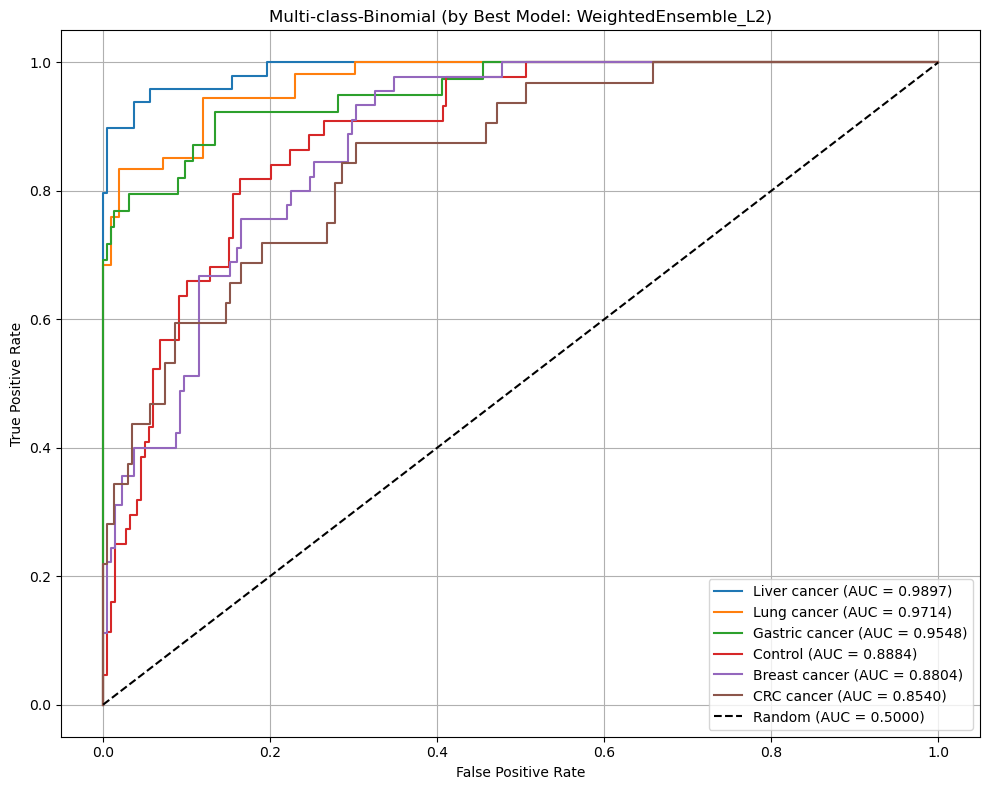

In [ ]:
def calculate_and_plot_multiclass_auc_Binomial(predictor, test_data, model_dir):
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize

    # 标签映射
    label_mapping = {
        0: 'Control',
        1: 'pancancer cancer',
        2: 'CRC cancer',
        3: 'Gastric cancer',
        4: 'Liver cancer',
        5: 'Lung cancer'
    }

    # 真实标签
    y_true = test_data[predictor.label]

    # 使用最佳模型进行预测
    best_model = predictor.model_best
    print(f"使用的最佳模型是: {best_model}")
    y_proba = predictor.predict_proba(test_data, model=best_model)

    # 转换真实标签为 One-vs-Rest 格式
    classes = predictor.class_labels
    y_true_bin = label_binarize(y_true, classes=classes)

    # 计算每个类别的 ROC 曲线和 AUC
    roc_data = []
    
    # for i, class_label in enumerate(classes):
    #     fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i])
    #     auc_val = auc(fpr, tpr)
    #     roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    for i, class_label in enumerate(classes):
        sample_weight = y_true_bin[:, i] * 5 + (1 - y_true_bin[:, i])  # 正类权重为 5，负类为 1
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba.iloc[:, i], sample_weight=sample_weight)
        auc_val = auc(fpr, tpr)
        roc_data.append((label_mapping[class_label], fpr, tpr, auc_val))

    # 按 AUC 从高到低排序
    roc_data.sort(key=lambda x: x[3], reverse=True)

    # 绘图
    plt.figure(figsize=(10, 8))
    for label, fpr, tpr, auc_val in roc_data:
        plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_val:.4f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5000)')
    plt.title(f"Multi-class-Binomial (by Best Model: {best_model})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

    # return {label: auc_val for label, _, _, auc_val in roc_data}

calculate_and_plot_multiclass_auc_Binomial(predictor, test_data, model_dir=model_dir)

### biomaker分析

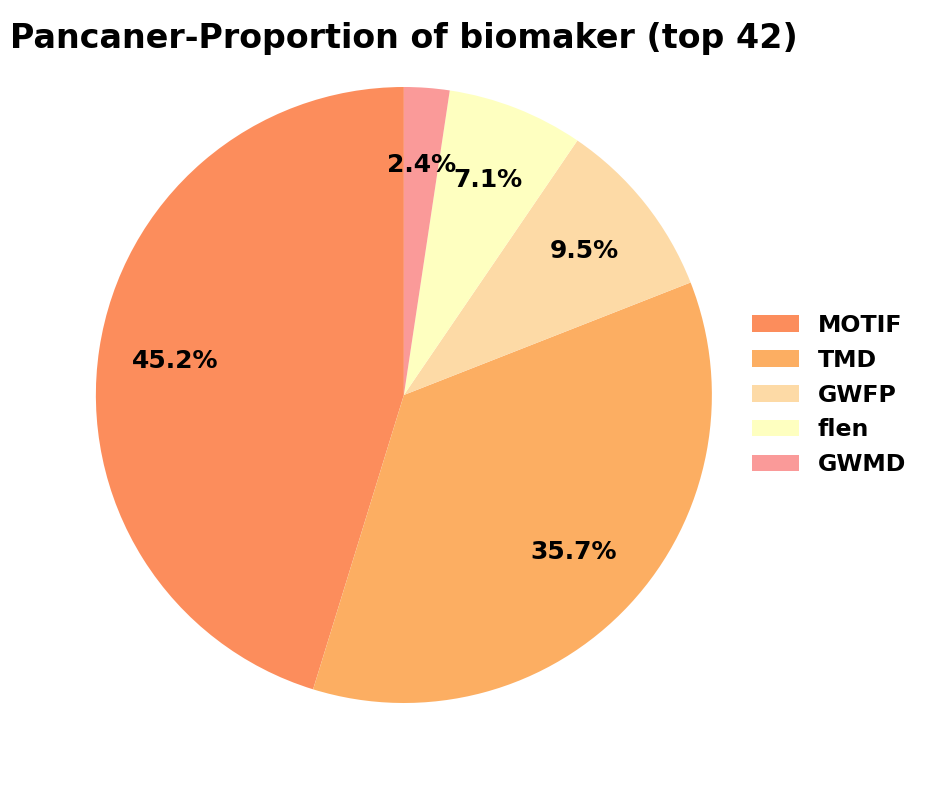

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '/home/xwluo/cfDNA/elife/ReliefF/pan_6_feature_importance2.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])
df = df.head(42)

# 判断每个Marker的类型，并将其分类
def classify_marker(marker):
    if "GWMD" in marker:
        return "GWMD"
    elif "TMD" in marker:
        return "TMD"
    elif "GWFP" in marker:
        return "GWFP"
    elif "flen" in marker:
        return "flen"
    elif "MOTIF" in marker:
        return "MOTIF"
    elif "CNA" in marker:
        return "CNA"
    else:
        return "Other"

# 将每个Marker进行分类
df['Type'] = df['Marker'].apply(classify_marker)

# 统计各类型的数量
type_counts = df['Type'].value_counts()

# 设置颜色
colors = [
    # '#e41b1d',
    # '#e8553c',
    # '#fdb963',
    # '#ffe797',
    # '#f69783',
    

    '#fc8d5c',
    '#fcae62',
    '#fddaa6',
    '#feffc0',
    '#fa9a99',
    

]
# 创建画布和饼图
fig, ax = plt.subplots(figsize=(10, 8))

wedges, texts, autotexts = ax.pie(
    type_counts,
    labels=None,  # 不显示板块外的分类名
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    textprops={'fontsize': 18, 'weight': 'bold'}

)

# 添加图例靠近图形，去掉边框
plt.legend(
    type_counts.index,
    bbox_to_anchor=(0.93, 0.5),  # 靠近饼图
    loc='center left',
    frameon=False,
    borderaxespad=0.3, 
    prop={'family': 'sans-serif', 'size': 17, 'weight': 'bold'}
)

# 标题
plt.title('Pancaner-Proportion of biomaker (top 42)', fontsize=24, fontweight='bold', y=0.94)

# 保持圆形 + 紧凑布局
# plt.axis('equal')
plt.tight_layout()
plt.savefig("pancancer-ReliefF-Proportion of Biomaker.png", dpi=300)
plt.show()